# Practical tasks

##### Please explore the datasets and answer the questions below.
##### Here are some guidlines and advices you should consider:
* you can add as many cells as is comfortable for you for each answer
* some questions require your explanation. Add a cell and choose a markdown option in the menu 
* when you are making plots, please add labels to the axes

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import scipy.cluster.hierarchy as shc

import seaborn as sns
from sklearn.cluster import KMeans
# you will need to import more libraries as needed

# Clustering tasks

The problem that we are going to solve in this section is to segment customers into different groups based on their shopping trends.

The dataset for this problem `shopping-data.csv`

#### 1. Load the data and preview

In [2]:
customer_data = pd.read_csv('shopping-data.csv')

In [3]:
customer_data.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
customer_data.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


#### 2. Plot scatter plot for annual income and spending score which will be used for clustering in the next steps

Text(0, 0.5, 'Spending Score (1-100)')

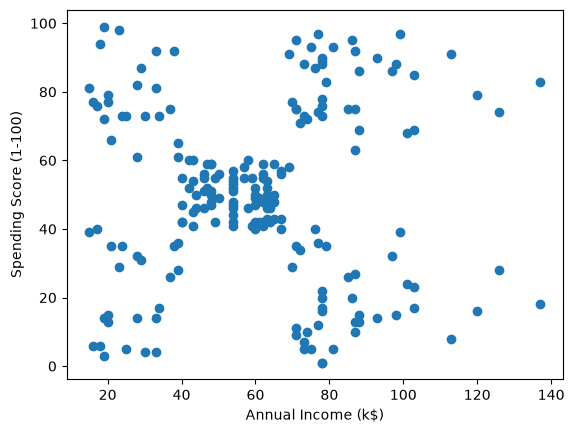

In [9]:
# <your code here>
plt.scatter(customer_data['Annual Income (k$)'], customer_data['Spending Score (1-100)'])
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')



#### 3. Normalize the data

In [11]:
# <your code here>
X=customer_data[['Annual Income (k$)','Spending Score (1-100)']]
scaler =StandardScaler()
customer_data_scaled= scaler.fit_transform(X)

#### 4. Use Elbow method to decide number of clusters

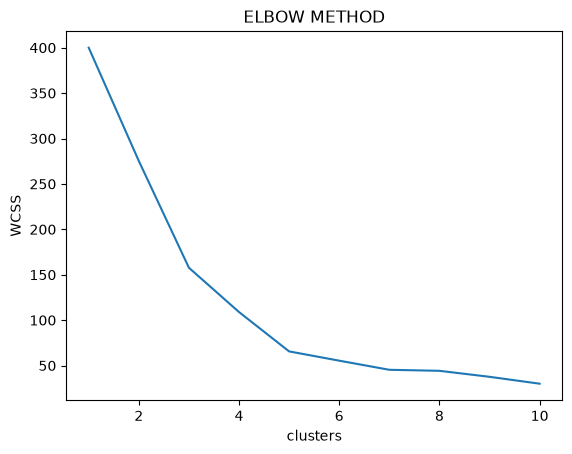

In [15]:
# <your code here>
elbow=[]
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=555, max_iter=200)
    kmeans.fit(customer_data_scaled)
    elbow.append(kmeans.inertia_)

plt.plot(range(1, 11), elbow)
plt.xlabel('clusters')
plt.ylabel('WCSS')

plt.title('ELBOW METHOD')
plt.show()

#### 5. Perform Clustering using KMeans

In [16]:
# <your code here>
kmeans = KMeans(n_clusters=5, max_iter=200)
clusters=kmeans.fit_predict(customer_data_scaled)


#### 6. Plot scatter plot and color code in clustered groups

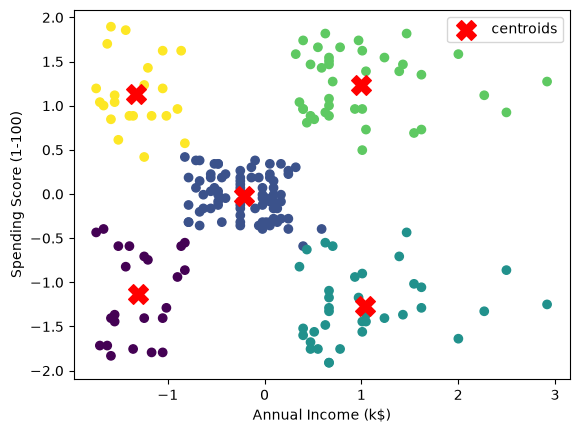

In [17]:
# <your code here>
plt.scatter(customer_data_scaled[:,0], customer_data_scaled[:,1],c=clusters,cmap='viridis')
plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1],c="red",marker="X",s=200,label="centroids")

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.show()

#### 7. Plot dendrogram to decide number of clusters for Hierarchical Clustering. <br> Explain (free text in a markdown cell) what is the optimal number of clusters and why

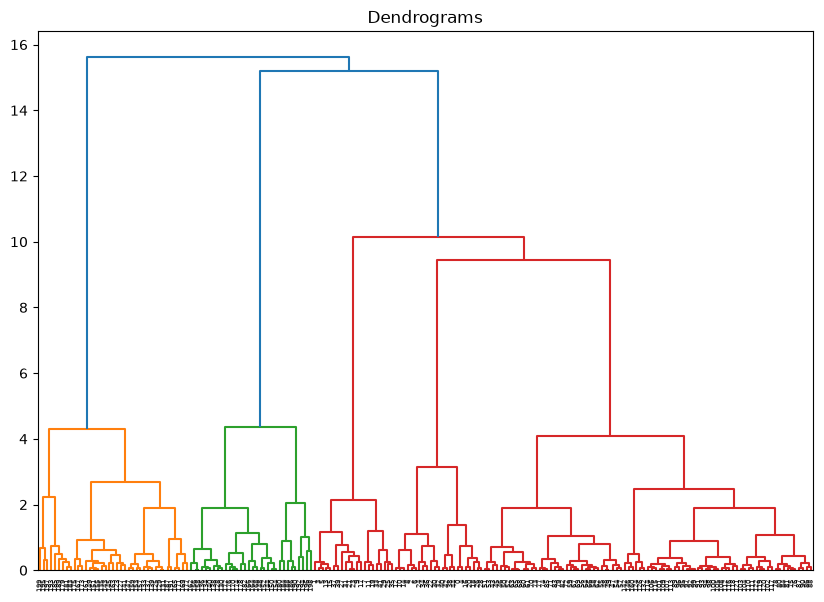

In [20]:
# <your code here>
plt.figure(figsize=(10, 7))  
plt.title("Dendrograms")  
dend = shc.dendrogram(shc.linkage(customer_data_scaled, method='ward'))
plt.show()

The optimal number of clusters is 5. In the dendrogam, the longest vertical distance that that is not crossed by any horizantal line that lies between the merges at the top. Cutting the dendrogam across this region intersects 5 vertical lines, and data splits into 5 groups.

#### 8. Do clustering using Hierarchical Clustering

In [22]:
# <your code here>
from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='ward')
hc_clusters = hc.fit_predict(customer_data_scaled)

#### 9. Plot scatter plot and color code in clustered groups

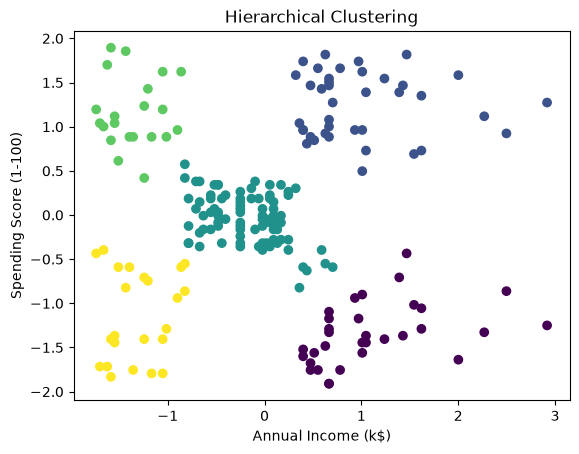

In [25]:
# <your code here>
plt.scatter(customer_data_scaled[:,0], customer_data_scaled[:,1],c=hc_clusters,cmap='viridis')

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Hierarchical Clustering')
plt.show()

####  10. Do KMeans and DBSCAN clustering on this data

In [26]:
from sklearn.datasets import make_moons
#moons_X: Data, moon_y: Labels
moons_X, moon_y = make_moons(n_samples=2000)

Text(0.5, 1.0, 'Half Moons')

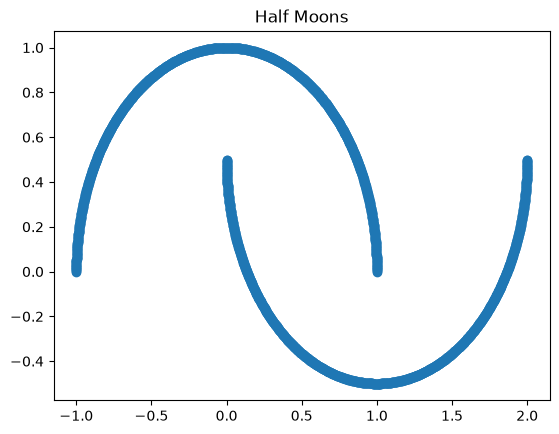

In [27]:
plt.scatter(moons_X[:,0],moons_X[:,1])
plt.title('Half Moons')

#### Using KMeans (do clustering and plot results (each cluster in own color))

In [62]:
# <your code here>
kmeans_moons = KMeans(n_clusters=2, max_iter=200)
kmeans_labels=kmeans_moons.fit_predict(moons_X)

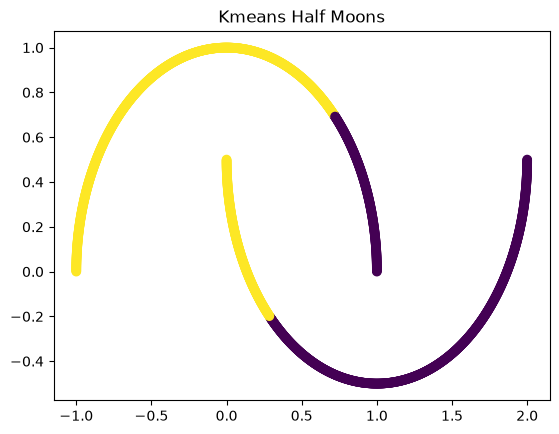

In [63]:
# <your code here>
plt.scatter(moons_X[:,0],moons_X[:,1], c=kmeans_labels, cmap="viridis")
plt.title('Kmeans Half Moons')
plt.show()


#### 11. Using DBSCAN do clustering and plot results (each cluster in own color). Find the most suitable eps and minimal samples number

In [60]:
# <your code here>
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.1, min_samples=2)
# fit model and predict clusters
yhat = dbscan.fit_predict(moons_X)
# retrieve unique clusters
clusters = np.unique(yhat)
clusters

array([0, 1])

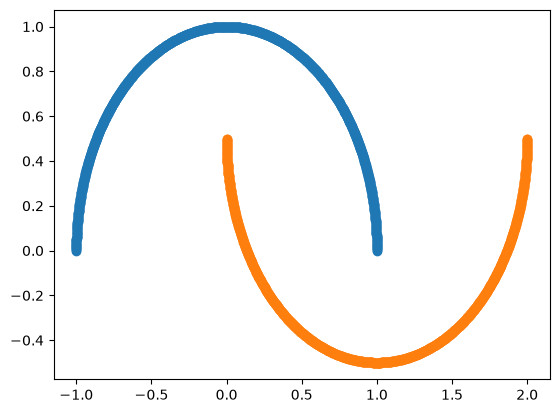

In [61]:
for cluster in clusters:
    # get row indexes for samples with this cluster
    row_ix = np.where(yhat == cluster)
    # create scatter of these samples
    plt.scatter(moons_X[row_ix, 0], moons_X[row_ix, 1])
plt.show()

#### 12. Compare the results of K-means and DBSCAN clustering
Explain why one or another is prefferable for such dataset, and differences if any.

K-means split the dta with a boundary between two halves, so each cluster contains part of both moons. DBSCAN separeted the two moons correctly, since it defines clusters as dense regions connected through neighboring points, so it followed the shape of the moons/curves.

### Perform PCA on penguins :)
###### This section uses kaggle dataset (https://www.kaggle.com/datasets/youssefaboelwafa/clustering-penguins-species/data)
###### The tasks below include data analysis, data preprocessing, PCA, and application of classification to predict the target

#### 13. Describe the data. Do any additional exporations as you feel

In [64]:
# Dataset
penguins = pd.read_csv('penguins.csv')
penguins.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE


In [70]:
# decribe the data, its size
# <your code here>
print('shape: ',penguins.shape)
penguins.info()
display(penguins.describe())

print(penguins['sex'].value_counts(dropna=False))
penguins.isna().sum()

shape:  (344, 5)
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   culmen_length_mm   342 non-null    float64
 1   culmen_depth_mm    342 non-null    float64
 2   flipper_length_mm  342 non-null    float64
 3   body_mass_g        342 non-null    float64
 4   sex                335 non-null    str    
dtypes: float64(4), str(1)
memory usage: 13.6 KB


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,214.014620,4201.754386
std,5.459584,1.974793,260.558057,801.954536
min,32.100000,13.100000,-132.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.750000,4750.000000
max,59.600000,21.500000,5000.000000,6300.000000


sex
MALE      169
FEMALE    165
NaN         9
.           1
Name: count, dtype: int64


culmen_length_mm     2
culmen_depth_mm      2
flipper_length_mm    2
body_mass_g          2
sex                  9
dtype: int64

#### Based on dataframe describe, in own words explain any abnormal characteristics 

2 rows have NaN in all numeric features, and sex has 9 missing values, it also contains an invalid value ".". There are also weird outliers like minimum flipper lenght being -132 and maximum being 5000.

<Double-click here to add your answer. Ctrl+Shift to enter>

#### 14. Explore corrupted data

In [72]:
# find missing values. print entries with missing values, provide shape
# <your code here>
print("Shape:",penguins.shape)
print(penguins.isna().sum())
missing_rows=penguins[penguins.isna().any(axis=1)]
print("rows with missing values: ",missing_rows.shape[0])
display(missing_rows)

Shape: (344, 5)
culmen_length_mm     2
culmen_depth_mm      2
flipper_length_mm    2
body_mass_g          2
sex                  9
dtype: int64
rows with missing values:  9


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
3,NaN,NaN,NaN,NaN,NaN
8,34.1,18.1,193.0,3475.0,NaN
10,37.8,17.1,186.0,3300.0,NaN
11,37.8,17.3,180.0,3700.0,NaN
47,37.5,18.9,179.0,2975.0,NaN
246,44.5,14.3,216.0,4100.0,NaN
286,46.2,14.4,214.0,4650.0,NaN
324,47.3,13.8,216.0,4725.0,NaN
339,NaN,NaN,NaN,NaN,NaN


In [74]:
# Examine sex column
# <your code here>
print(penguins['sex'].value_counts(dropna=False))
display(penguins[penguins['sex']=='.'])

sex
MALE      169
FEMALE    165
NaN         9
.           1
Name: count, dtype: int64


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
336,44.5,15.7,217.0,4875.0,.


In [77]:
# find any unusual values. Print anomal rows
# <your code here>
anomalies= penguins[(penguins['flipper_length_mm']<150) | (penguins['flipper_length_mm']>250)]
display(anomalies)

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
9,42.0,20.2,5000.0,4250.0,MALE
14,34.6,21.1,-132.0,4400.0,MALE


#### 15. Based on observations above, prepare the data for PCA. Only valid rows should be present. <br> Preview dataframe, show its size

In [81]:
# clean
# <your code here>
penguins_clean= penguins.dropna().copy()
penguins_clean= penguins_clean[penguins_clean['sex'].isin(['MALE','FEMALE'])]
penguins_clean= penguins_clean[penguins_clean['flipper_length_mm'].between(150,250)]
penguins_clean= penguins_clean.reset_index(drop=True)

print("Size: ",penguins_clean.shape)
display(penguins_clean.head())

Size:  (332, 5)


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,36.7,19.3,193.0,3450.0,FEMALE
4,39.3,20.6,190.0,3650.0,MALE


In [105]:
# scale numerical columns. assign to a variable X_penguins
# <your code here>
num_cols= ['culmen_length_mm','culmen_depth_mm','flipper_length_mm',"body_mass_g"]
X_penguins= StandardScaler().fit_transform(penguins_clean[num_cols])
print(X_penguins.shape)

(332, 4)


In [84]:
# assign categorical column to a variable y_penguins
# <your code here>
y_penguins=penguins_clean['sex']
print(y_penguins.value_counts())

sex
MALE      167
FEMALE    165
Name: count, dtype: int64


#### 15. Explain the chosen null values handling strategy, how it affects the dataset (pros/cons)

<Double-click here to add your answer. Ctrl+Shift to enter>
I removed every row that was not valid (missing values), the rows with invalid sex value "." and impossible flipper lengths ware also droped. Pros: Its simple and no invented data, and makes the data usable right away. Cons: Information is lost, 12 of 344 rows, rows with missing sex value had  valid measurements, that could have been kept. It also can itroduce bias.

#### 16. Perform PCA with 2 components. Plot the results 

Shape after PCA: (332, 2)

Explained variance ratio: [0.68713344 0.19641564]
Total variance explained: 88.35%


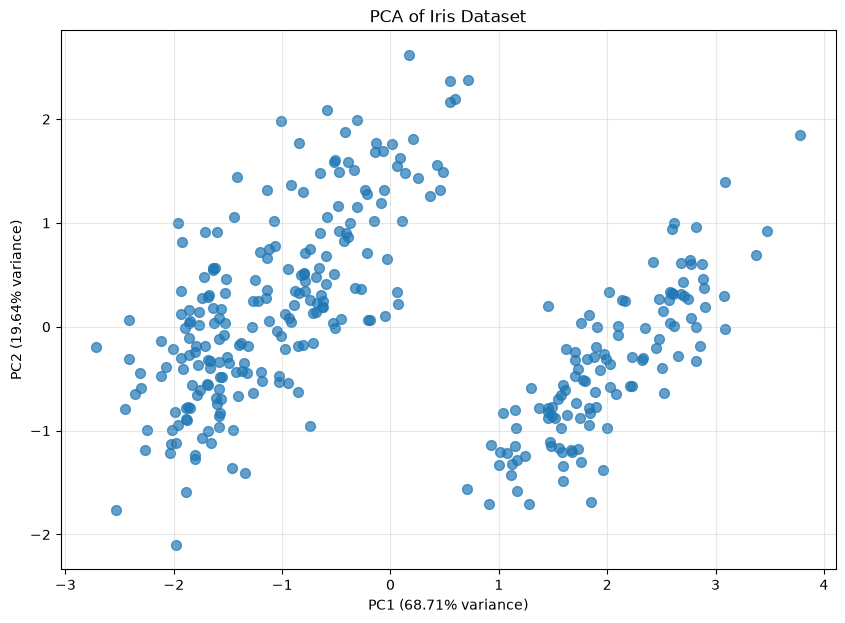

In [110]:
# <your code here>
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_penguins)

print(f"Shape after PCA: {X_pca.shape}")
print(f"\nExplained variance ratio: {pca.explained_variance_ratio_}")
print(f"Total variance explained: {pca.explained_variance_ratio_.sum():.2%}")


plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], s=50, alpha=0.7)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%} variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%} variance)')
plt.title('PCA of Iris Dataset')
plt.grid(True, alpha=0.3)
plt.show()

#### 17. Display scree plots to determine the optimal number of components and cumulative explained variance

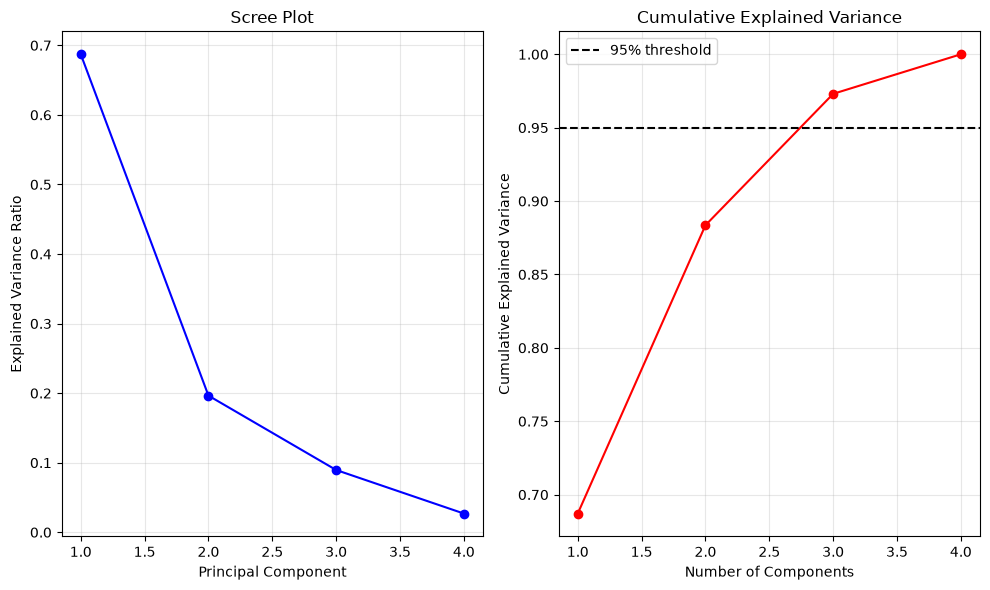

Explained variance by each component:
PC1: 68.71%
PC2: 19.64%
PC3: 8.95%
PC4: 2.69%


In [ ]:
# <your code here>
pca_full = PCA()
pca_full.fit(X_penguins)

plt.figure(figsize=(10, 6))
plt.subplot(1, 2, 1)
plt.plot(range(1, len(pca_full.explained_variance_ratio_) + 1), 
         pca_full.explained_variance_ratio_, 'bo-')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.title('Scree Plot')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(range(1, len(pca_full.explained_variance_ratio_) + 1),
         np.cumsum(pca_full.explained_variance_ratio_), 'ro-')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Cumulative Explained Variance')
plt.axhline(y=0.95, color='k', linestyle='--', label='95% threshold')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Explained variance by each component:")
for i, var in enumerate(pca_full.explained_variance_ratio_):
    print(f"PC{i+1}: {var:.2%}")

Looks to that 3 components are the better choice.

#### 18. Calculate (show in numbers) and display component loadings

In [111]:
# Component loadings (how much each original feature contributes to each PC)
# <your code here>
components_df = pd.DataFrame(
    pca.components_.T,
    columns=['PC1', 'PC2'],
    index=num_cols
)

print("Component loadings (feature contributions to PCs):")
print(components_df)


Component loadings (feature contributions to PCs):
                        PC1       PC2
culmen_length_mm   0.453174  0.604990
culmen_depth_mm   -0.398518  0.792959
flipper_length_mm  0.576880  0.003798
body_mass_g        0.550478  0.072032


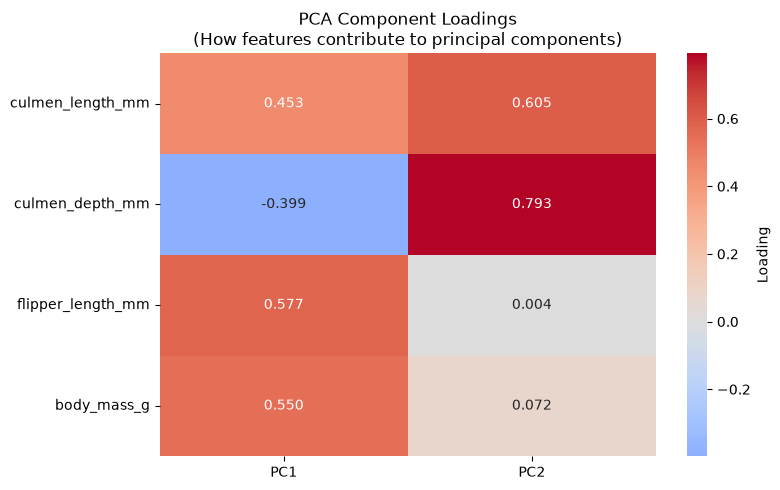

In [112]:
# show heatmap
# <your code here>

plt.figure(figsize=(8, 5))
sns.heatmap(components_df, annot=True, cmap='coolwarm', center=0, 
            cbar_kws={'label': 'Loading'}, fmt='.3f')
plt.title('PCA Component Loadings\n(How features contribute to principal components)')
plt.tight_layout()
plt.show()

#### 19. Perform logistic regression (or any other classification algorithm) and evaluate the model

In [135]:
# import necessary libraries for model training and evaluation
# Use the PCA-transformed data (X_penguins_pca) and true labels (y_penguins)
# Train and evaluate a model
# <your code here>
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score

X_penguins_pca=X_pca

X_train, X_test, y_train, y_test = train_test_split(
   X_penguins_pca , y_penguins, test_size=0.2, random_state=40)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

model=LogisticRegression()
model.fit(X_train,y_train)
y_pred=model.predict(X_test)

print("accuracy: ",accuracy_score(y_test, y_pred)),


(265, 2) (265,) (67, 2) (67,)
accuracy:  0.8059701492537313


(None,)

#### 20. Train the model on all data points, and determine penguin sex for the data, where it was not originally identified

In [129]:
# 1. take entries from original data with sex unknown, scale numerical columns
# <your code here>
unknown=penguins[penguins['sex'].isna()].copy()
unknown=unknown.dropna(subset=num_cols)
unknown=unknown[unknown['flipper_length_mm'].between(150,250)]

scaler= StandardScaler().fit(penguins_clean[num_cols])
X_unknown_scaled=scaler.transform(unknown[num_cols])
print("unknown",unknown.shape[0])
display(unknown)

unknown 7


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
8,34.1,18.1,193.0,3475.0,NaN
10,37.8,17.1,186.0,3300.0,NaN
11,37.8,17.3,180.0,3700.0,NaN
47,37.5,18.9,179.0,2975.0,NaN
246,44.5,14.3,216.0,4100.0,NaN
286,46.2,14.4,214.0,4650.0,NaN
324,47.3,13.8,216.0,4725.0,NaN


In [130]:
# 2. apply the same PCA transformation to the new data
# <your code here>
X_unknown_pca=pca.transform(X_unknown_scaled)
print(X_unknown_pca.shape)

(7, 2)


In [133]:
# 3. Train the model
# Define X_train and y_train using all PCA data from valid data
# <your code here>
X_train=X_penguins_pca
y_train=y_penguins
# Train a classifier
# <your code here>
final_model=LogisticRegression()
final_model.fit(X_train, y_train)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [134]:
# 4. Make predictions on the new data. Display the features and predicted values
# <your code here>
unknown['predicted_sex']=final_model.predict(X_unknown_pca)

print("prediction made for", unknown.shape[0],"penguins")
display(unknown[num_cols +['predicted_sex']])
print(unknown['predicted_sex'].value_counts())

prediction made for 7 penguins


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,predicted_sex
8,34.1,18.1,193.0,3475.0,FEMALE
10,37.8,17.1,186.0,3300.0,FEMALE
11,37.8,17.3,180.0,3700.0,FEMALE
47,37.5,18.9,179.0,2975.0,FEMALE
246,44.5,14.3,216.0,4100.0,FEMALE
286,46.2,14.4,214.0,4650.0,FEMALE
324,47.3,13.8,216.0,4725.0,FEMALE


predicted_sex
FEMALE    7
Name: count, dtype: int64
